In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/ayushbharti96/electric-vehicle-ev-dataset/EV data by country 2026.csv


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error


In [3]:
df = pd.read_csv('/kaggle/input/datasets/ayushbharti96/electric-vehicle-ev-dataset/EV data by country 2026.csv')

In [4]:
#Display the first 10 rows.
df.head(10)

,region_country,category,parameter,mode,powertrain,year,unit,value,Aggregate group
0,Chile,Historical,EV charging points,EVSE,Publicly available fast,2011,charging points,1.0,Other
1,Norway,Historical,EV charging points,EVSE,Publicly available fast,2011,charging points,18.0,Other
2,Portugal,Historical,EV charging points,EVSE,Publicly available fast,2011,charging points,6.0,Other
3,Canada,Historical,EV charging points,EVSE,Publicly available fast,2012,charging points,2.0,Other
4,Chile,Historical,EV charging points,EVSE,Publicly available fast,2012,charging points,4.0,Other
5,France,Historical,EV charging points,EVSE,Publicly available fast,2012,charging points,9.0,Other
6,Germany,Historical,EV charging points,EVSE,Publicly available fast,2012,charging points,18.0,Other
7,Italy,Historical,EV charging points,EVSE,Publicly available fast,2012,charging points,1.0,Other
8,Netherlands,Historical,EV charging points,EVSE,Publicly available fast,2012,charging points,21.0,Other
9,Norway,Historical,EV charging points,EVSE,Publicly available fast,2012,charging points,58.0,Other


In [5]:
#	Find the number of rows and columns.
df.shape

(49375, 9)

In [6]:
#Display all column names.
df.columns

Index(['region_country', 'category', 'parameter', 'mode', 'powertrain', 'year',
       'unit', 'value', 'Aggregate group'],
      dtype='object')

In [7]:
#Check the data types.
df.dtypes

region_country      object
category            object
parameter           object
mode                object
powertrain          object
year                 int64
unit                object
value              float64
Aggregate group     object
dtype: object

In [8]:
#Find missing values in every column.
df.isnull().sum()

region_country      1078
category               0
parameter              0
mode                   0
powertrain             0
year                   0
unit               22582
value                  0
Aggregate group        0
dtype: int64

In [9]:
#	Find duplicate records.
df.duplicated()

0        False
1        False
2        False
3        False
4        False
         ...  
49370    False
49371    False
49372    False
49373    False
49374    False
Length: 49375, dtype: bool

In [10]:
#Find the number of unique countries.
df['region_country'].nunique()

72

In [11]:
#Find all unique EV powertrains.
df['powertrain'].nunique()

10

In [12]:
#Find the minimum and maximum year.
print("Minimum Year:", df['year'].min())
print("Maximum Year:", df['year'].max())           

Minimum Year: 2010
Maximum Year: 2035


In [13]:
#	Generate descriptive statistics.
df.describe()

,year,value
count,49375.000000,4.937500e+04
mean,2018.923828,3.203183e+05
std,4.956759,5.547735e+06
min,2010.000000,1.000000e-06
25%,2015.000000,6.000000e+01
50%,2019.000000,1.700000e+04
75%,2022.000000,6.200000e+04
max,2035.000000,4.700000e+08


In [14]:
#	Identify missing values.
df.drop_duplicates()

,region_country,category,parameter,mode,powertrain,year,unit,value,Aggregate group
0,Chile,Historical,EV charging points,EVSE,Publicly available fast,2011,charging points,1.0,Other
1,Norway,Historical,EV charging points,EVSE,Publicly available fast,2011,charging points,18.0,Other
2,Portugal,Historical,EV charging points,EVSE,Publicly available fast,2011,charging points,6.0,Other
3,Canada,Historical,EV charging points,EVSE,Publicly available fast,2012,charging points,2.0,Other
4,Chile,Historical,EV charging points,EVSE,Publicly available fast,2012,charging points,4.0,Other
...,...,...,...,...,...,...,...,...,...
49370,World,Projection-STEPS,EV stock,2 and 3 wheelers,EV,2035,Vehicles,300000000.0,_World
49371,World,Projection-STEPS,EV stock,Buses,EV,2035,Vehicles,3600000.0,_World
49372,World,Projection-STEPS,EV stock,Cars,EV,2035,Vehicles,470000000.0,_World
49373,World,Projection-STEPS,EV stock,Trucks,EV,2035,Vehicles,10000000.0,_World


In [15]:
#Remove duplicate records.
df = df.drop_duplicates()

print(df.duplicated().sum())

0


In [16]:
#	Check missing country names.
df['region_country'].isnull().sum()

np.int64(1078)

In [17]:
#Identify whether missing values are important or intentional.
df[df['region_country'].isnull() | df['unit'].isnull()][['region_country', 'unit', 'parameter', 'Aggregate group']].head(10)

,region_country,unit,parameter,Aggregate group
20719,Australia,NaN,price_p0_2025USD,Other
20720,Australia,NaN,price_p0_2025USD,Other
20721,Australia,NaN,price_p0_2025USD,Other
20722,Australia,NaN,price_p0_2025USD,Other
20723,Australia,NaN,price_p0_2025USD,Other
20724,Brazil,NaN,price_p0_2025USD,Other
20725,Brazil,NaN,price_p0_2025USD,Other
20726,Brazil,NaN,price_p0_2025USD,Other
20727,Brazil,NaN,price_p0_2025USD,Other
20728,Brazil,NaN,price_p0_2025USD,Other


In [18]:
#Check invalid or negative values.
(df['value'] < 0).sum()

np.int64(0)

In [19]:
#Separate historical data and projection data.
historical = df[df['category'] == 'Historical'].shape
projection = df[df['category'] != 'Historical'].shape

historical
projection

(1261, 9)

In [20]:
#Check whether units are consistent.
df.groupby('parameter')['unit'].unique()

parameter
Average capacity per EV                                          [kW/EV]
Average capacity per EVSE                                      [kW/EVSE]
Battery deployment                                                 [GWh]
EV charging points                                     [charging points]
EV sales                                                      [Vehicles]
EV sales share                                                 [percent]
EV stock                                                      [Vehicles]
EV stock share                                                 [percent]
Electric LDVs per charging point                              [vehicles]
Electricity demand                                                 [GWh]
Oil displacement Mlge               [Million litres gasoline equivalent]
Oil displacement, Mbd                          [Million barrels per day]
price_mean_2025USD                                                 [nan]
price_p0_2025USD                         

In [21]:
#Which country has the highest EV sales?
sales = df[
    (df['parameter'] == 'EV sales') &
    (df['category'] == 'Historical') &
    (df['year'] == 2025) &
    (df['powertrain'] == 'EV')
]
country_sales =(
    sales.groupby('region_country')['value'].sum().sort_values(ascending=False)
)
print(country_sales.head(10))

region_country
World                               32940000.0
Asia Pacific                        25659000.0
China                               20980000.0
Advanced Economies                   7158000.0
Europe                               4700000.0
Developing Economies excl. China     4530900.0
European Union                       3152700.0
India                                2283500.0
USA                                  1515900.0
Southeast Asia                       1423120.0
Name: value, dtype: float64


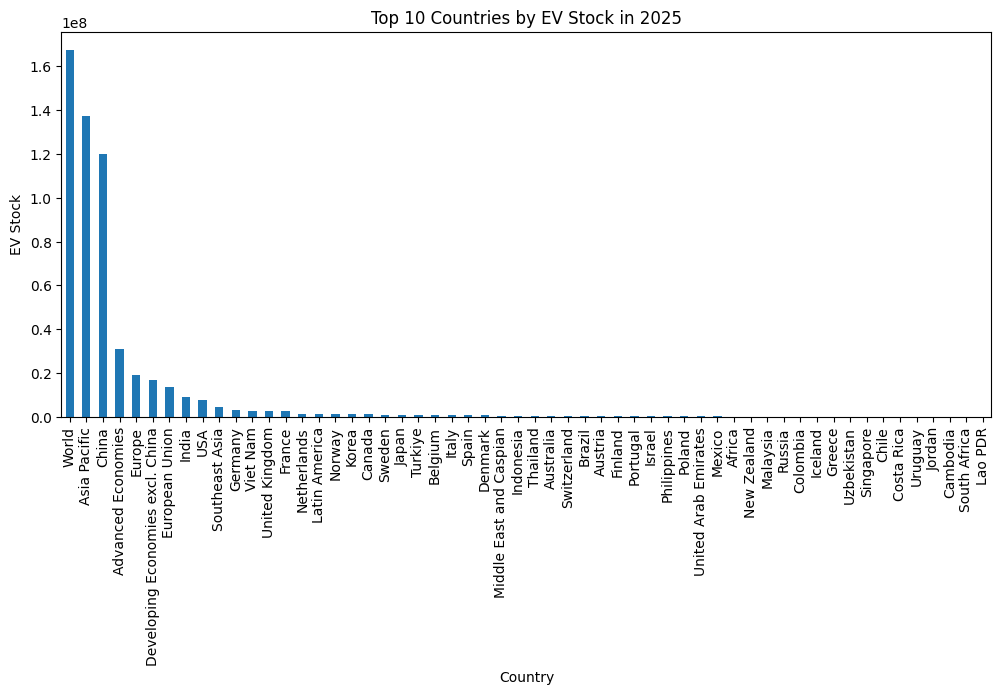

In [22]:
#Which country has the highest EV stock?
# Which country has the highest EV stock?

stock = df[
    (df['parameter'] == 'EV stock') &
    (df['category'] == 'Historical') &
    (df['year'] == 2025) &
    (df['powertrain'] == 'EV')
]

top_countries = (
    stock.groupby('region_country')['value']
    .sum()
    .sort_values(ascending=False)
)

top_countries.head()
top_countries.plot(
    kind='bar',
    figsize=(12, 5),
    title='Top 10 Countries by EV Stock in 2025'
)

plt.ylabel('EV Stock')
plt.xlabel('Country')
plt.show()

year
2010    2.022760e+05
2011    3.185470e+05
2012    6.722421e+06
2013    8.033892e+06
2014    9.893087e+06
2015    1.060168e+07
2016    1.279619e+07
2017    1.592764e+07
2018    2.321636e+07
2019    2.852399e+07
2020    3.926625e+07
2021    6.011174e+07
2022    6.808742e+07
2023    8.216783e+07
2024    9.176639e+07
2025    1.123098e+08
Name: value, dtype: float64


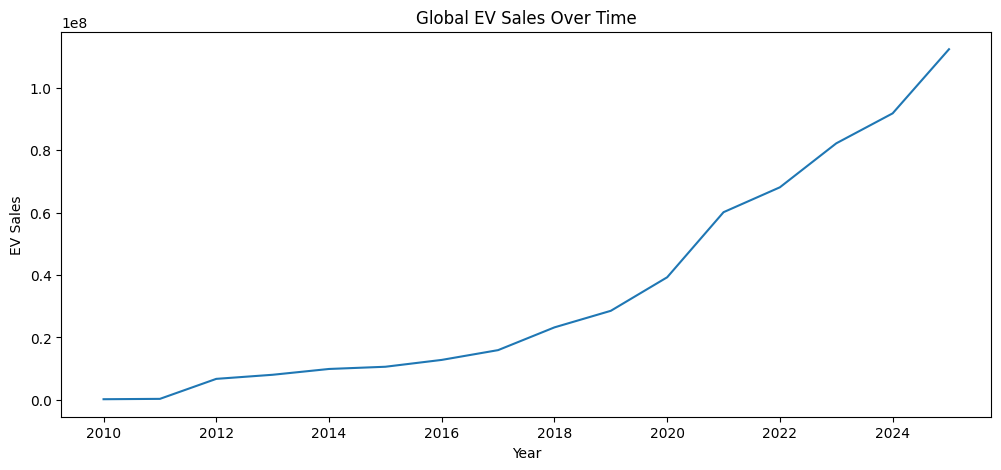

In [23]:
#Which year recorded the highest EV sales?
year_sales = df[
(df['parameter'] == 'EV sales')&
(df['category'] == "Historical")&
(df['powertrain'] == 'EV')
]
yearly_sales = year_sales.groupby('year')['value'].sum()
print(yearly_sales)

plt.figure(figsize=(12,5))
sns.lineplot(x=yearly_sales.index , y=yearly_sales.values)
plt.title('Global EV Sales Over Time')
plt.xlabel('Year')
plt.ylabel('EV Sales')
plt.show()

powertrain
BEV     4.791145e+08
PHEV    9.263127e+07
Name: value, dtype: float64


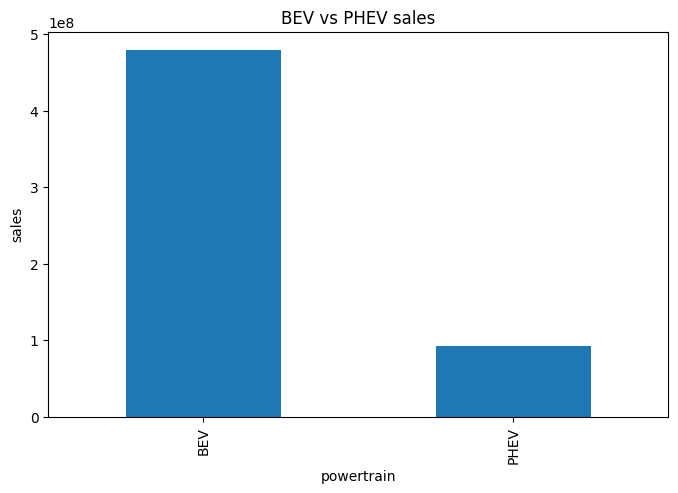

In [24]:
#Compare BEV and PHEV sales.
bev = df[
(df['parameter']== 'EV sales')&
(df['category'] == 'Historical')&
(df['powertrain'].isin(['BEV' ,'PHEV']))
]
comparison =(
    bev.groupby('powertrain')['value'].sum()
)
print(comparison)

comparison.plot(
    kind ='bar',
    figsize=(8,5),
    title ='BEV vs PHEV sales'
)
plt.ylabel('sales')
plt.show()

In [25]:
#Analyze EV sales growth over time.
yearly = (
    df[
        (df['parameter'] == 'EV sales') &
        (df['category'] == 'Historical') &
        (df['powertrain'] == 'EV')
    ]
    .groupby('year')['value']
    .sum()
    .sort_index()
)

growth = yearly.pct_change() * 100

result = pd.DataFrame({
    'EV Sales': yearly,
    'Growth Percentage': growth
})

print(result)

          EV Sales  Growth Percentage
year                                 
2010  2.022760e+05                NaN
2011  3.185470e+05          57.481362
2012  6.722421e+06        2010.338820
2013  8.033892e+06          19.508909
2014  9.893087e+06          23.141897
2015  1.060168e+07           7.162459
2016  1.279619e+07          20.699678
2017  1.592764e+07          24.471718
2018  2.321636e+07          45.761489
2019  2.852399e+07          22.861609
2020  3.926625e+07          37.660438
2021  6.011174e+07          53.087536
2022  6.808742e+07          13.268101
2023  8.216783e+07          20.679896
2024  9.176639e+07          11.681654
2025  1.123098e+08          22.386597


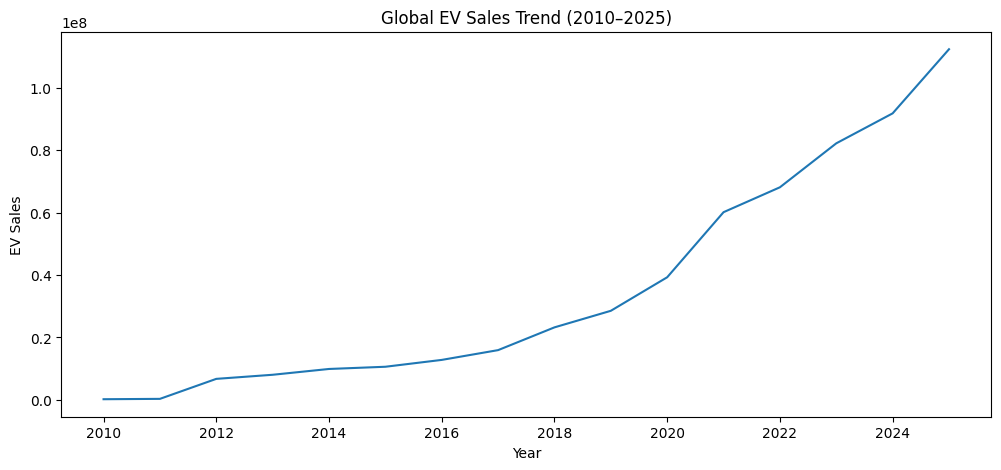

In [26]:
#EV sales trend from 2010–2025
year_sales = df[
(df['parameter'] == 'EV sales')&
(df['category'] == 'Historical')&
(df['powertrain'] == 'EV')&
(df['year'].between(2010,2025))
]

yearly_sales = year_sales.groupby('year')['value'].sum()

plt.figure(figsize=(12,5))
sns.lineplot(x=yearly_sales.index , y=yearly_sales.values)
plt.title('Global EV Sales Trend (2010–2025)')
plt.xlabel('Year')
plt.ylabel('EV Sales')
plt.show()


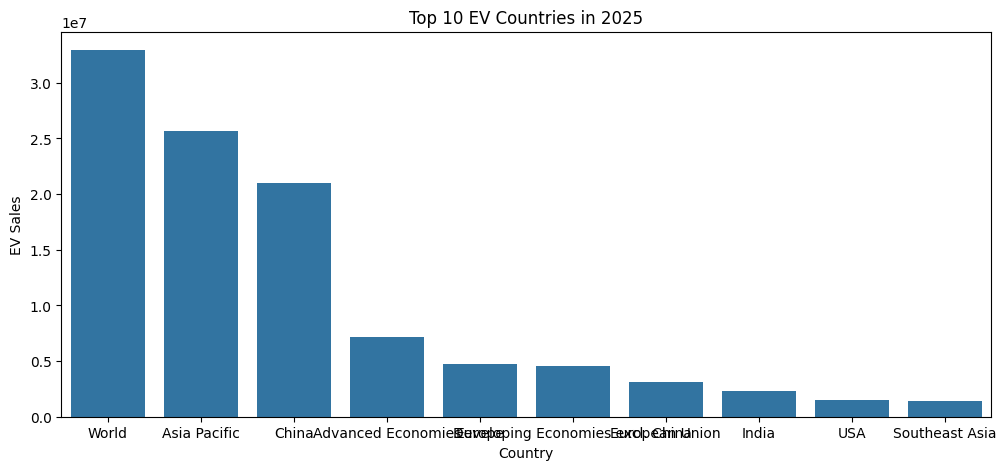

In [27]:
# Top 10 EV countries
sales = df[
(df['parameter'] == 'EV sales')&
(df['category'] == 'Historical')&
(df['year'] == 2025)&
(df['powertrain'] == 'EV')
]

top_10 = sales.groupby('region_country')['value'].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(12,5))
sns.barplot(x=top_10.index, y=top_10.values)

plt.title('Top 10 EV Countries in 2025')
plt.xlabel('Country')
plt.ylabel('EV Sales')
plt.show()

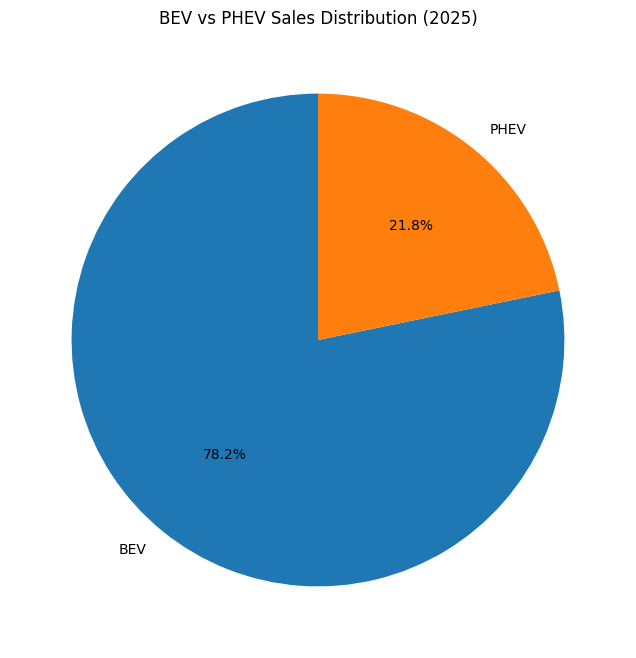

In [28]:
#Pie chart	BEV vs PHEV sales distribution
# BEV vs PHEV sales distribution

bev_phev = df[
    (df['parameter'] == 'EV sales') &
    (df['category'] == 'Historical') &
    (df['year'] == 2025) &
    (df['powertrain'].isin(['BEV', 'PHEV']))
]

comparison = bev_phev.groupby('powertrain')['value'].sum()

plt.figure(figsize=(8, 8))
plt.pie(comparison.values, labels=comparison.index, autopct='%1.1f%%', startangle=90)

plt.title('BEV vs PHEV Sales Distribution (2025)')
plt.show()

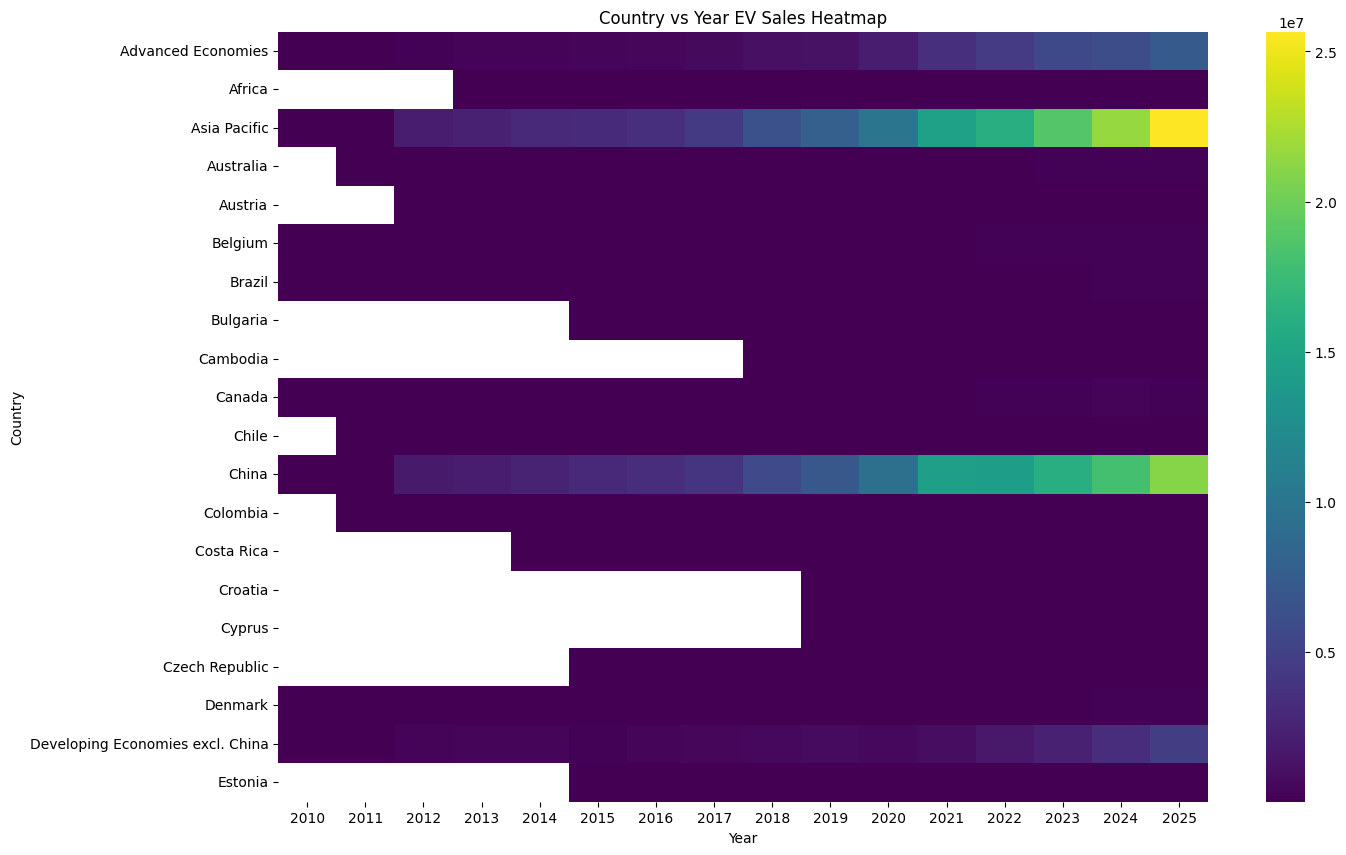

In [29]:
#Country vs year EV sales
sales = df[
    (df['parameter'] == 'EV sales') &
    (df['category'] == 'Historical') &
    (df['powertrain'] == 'EV')
]

pivot = sales.pivot_table(
    index='region_country',
    columns='year',
    values='value',
    aggfunc='sum'
)

plt.figure(figsize=(15, 10))
sns.heatmap(pivot.head(20), cmap='viridis')

plt.title('Country vs Year EV Sales Heatmap')
plt.xlabel('Year')
plt.ylabel('Country')
plt.show()

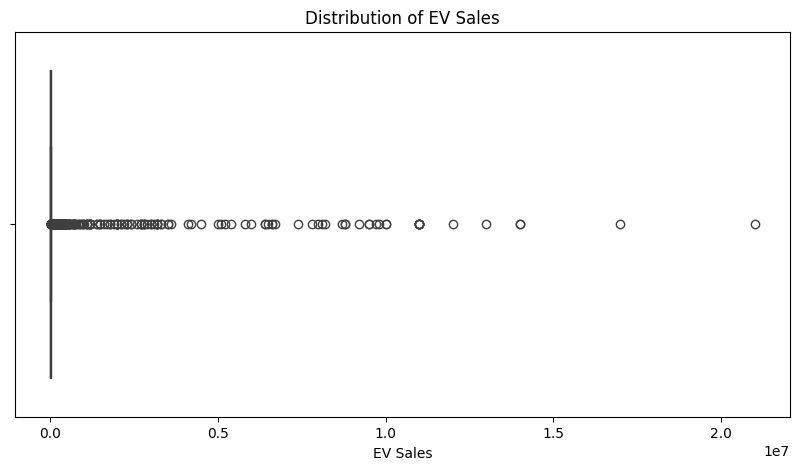

In [30]:
#Distribution of EV sales
sales = df[
    (df['parameter'] == 'EV sales') &
    (df['category'] == 'Historical') &
    (df['powertrain'] == 'EV')
]

plt.figure(figsize=(10, 5))
sns.boxplot(x=sales['value'])

plt.title('Distribution of EV Sales')
plt.xlabel('EV Sales')
plt.show()

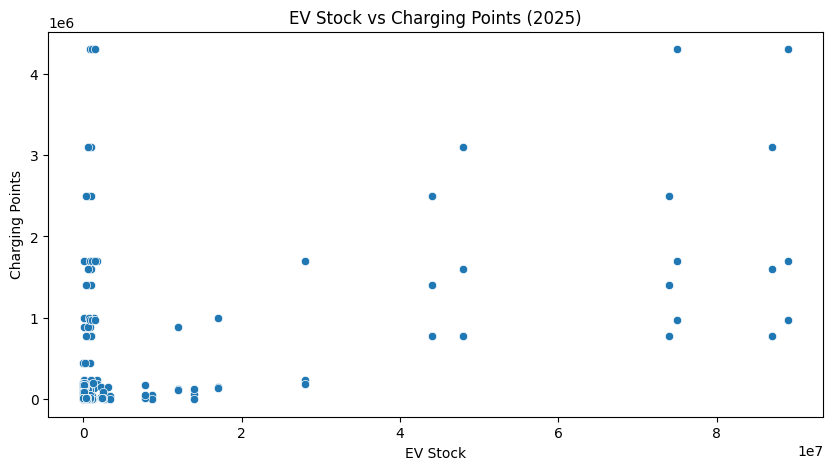

In [31]:
#EV stock vs charging points
stock = df[
    (df['parameter'] == 'EV stock') &
    (df['category'] == 'Historical') &
    (df['year'] == 2025) &
    (df['powertrain'] == 'EV')
]

charging = df[
    (df['parameter'] == 'EV charging points') &
    (df['category'] == 'Historical') &
    (df['year'] == 2025)
]

merged = pd.merge(
    stock,
    charging,
    on='region_country',
    suffixes=('_stock', '_charging')
)

plt.figure(figsize=(10, 5))
sns.scatterplot(
    x=merged['value_stock'],
    y=merged['value_charging']
)

plt.title('EV Stock vs Charging Points (2025)')
plt.xlabel('EV Stock')
plt.ylabel('Charging Points')
plt.show()

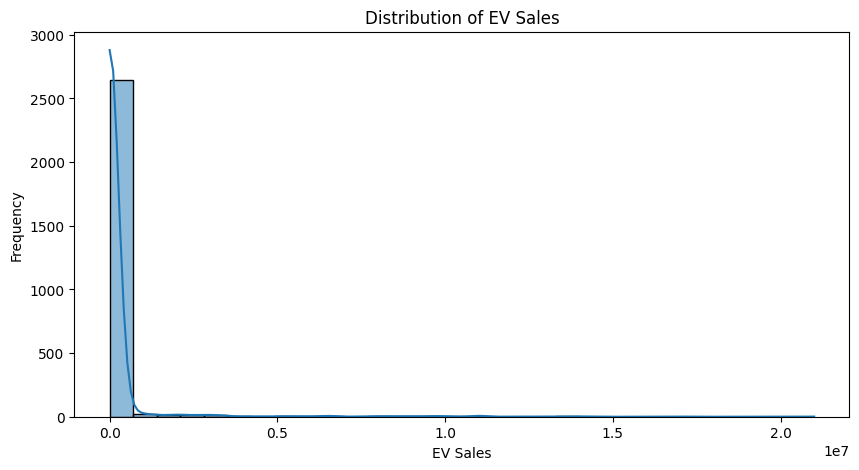

In [32]:
#Distribution of EV sales
sales = df[
    (df['parameter'] == 'EV sales') &
    (df['category'] == 'Historical') &
    (df['powertrain'] == 'EV')
]

plt.figure(figsize=(10, 5))
sns.histplot(x=sales['value'], bins=30, kde=True)

plt.title('Distribution of EV Sales')
plt.xlabel('EV Sales')
plt.ylabel('Frequency')
plt.show()

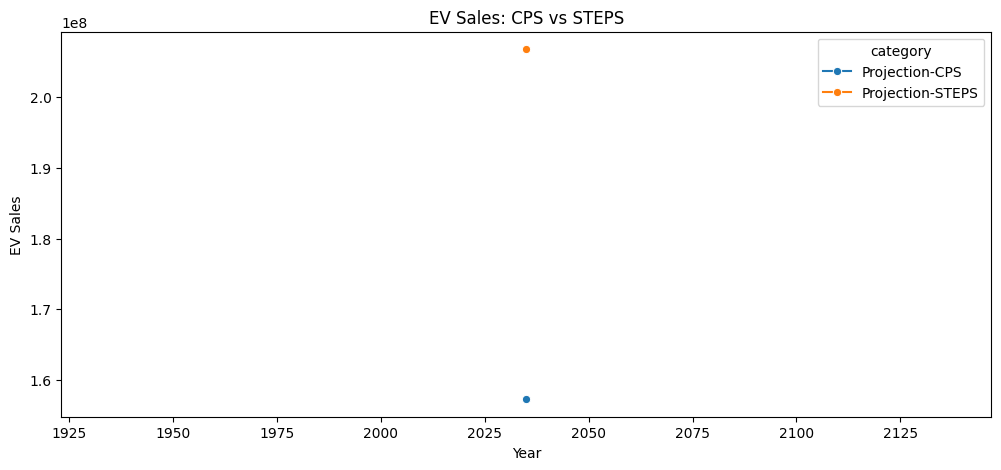

In [33]:
#Multiple line plot	CPS vs STEPS
scenario = df[
    (df['parameter'] == 'EV sales') &
    (df['category'].isin(['Projection-CPS', 'Projection-STEPS'])) &
    (df['powertrain'] == 'EV')
]

yearly_sales = scenario.groupby(
    ['year', 'category']
)['value'].sum().reset_index()

plt.figure(figsize=(12, 5))
sns.lineplot(data=yearly_sales, x='year', y='value', hue='category', marker='o')

plt.title('EV Sales: CPS vs STEPS')
plt.xlabel('Year')
plt.ylabel('EV Sales')
plt.show()

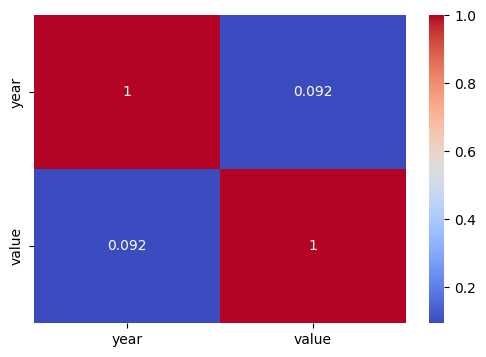

In [34]:
#Numerical feature relationships
numeric = df[['year', 'value']]

plt.figure(figsize=(6, 4))

sns.heatmap(
    numeric.corr(),
    annot=True,
    cmap='coolwarm'
)

plt.show()

In [35]:
#Calculate EV sales growth rate for every country.
yearly_sales = df.groupby(['region_country', 'year'])['value'].sum().reset_index()

yearly_sales['Growth Rate (%)'] = yearly_sales.groupby('region_country')['value'].pct_change() * 100

yearly_sales

,region_country,year,value,Growth Rate (%)
0,Advanced Economies,2010,1.117687e+05,NaN
1,Advanced Economies,2011,3.384860e+05,202.845088
2,Advanced Economies,2012,7.871827e+05,132.559940
3,Advanced Economies,2013,1.374181e+06,74.569461
4,Advanced Economies,2014,2.110008e+06,53.546631
...,...,...,...,...
967,World,2022,2.044963e+08,21.440514
968,World,2023,2.743856e+08,34.176312
969,World,2024,3.332541e+08,21.454660
970,World,2025,4.093130e+08,22.823117


In [36]:
#Calculate EV market share for each country.
market_share = df[
    (df['parameter'] == 'EV sales share') &
    (df['category'] == 'Historical') &
    (df['year'] == 2025) &
    (df['powertrain'] == 'EV')
]

market_share.groupby('region_country')['value'].sum().sort_values(ascending=False)

region_country
Norway                  236.000
Denmark                 230.000
United Arab Emirates    229.000
China                   205.000
Netherlands             186.000
                         ...   
Cambodia                  5.450
Croatia                   5.400
South Africa              4.720
Africa                    3.165
Russia                    2.560
Name: value, Length: 70, dtype: float64

In [37]:
#Find the country with the fastest EV adoption.
yearly_sales = df.groupby(['region_country', 'year'])['value'].sum().reset_index()

yearly_sales['Growth Rate (%)'] = yearly_sales.groupby('region_country')['value'].pct_change() * 100

yearly_sales.groupby('region_country')['Growth Rate (%)'].mean().sort_values(ascending=False).head(1)

region_country
Indonesia    8.970279e+06
Name: Growth Rate (%), dtype: float64

In [38]:
#Compare EV sales in 2015, 2020 and 2025.
pivot = sales.pivot_table(
    index='region_country',
    columns='year',
    values='value',
    aggfunc='sum'
)

pivot

year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
region_country,,,,,,,,,,,,,,,,
Advanced Economies,7247.0,45846.0,132097.0,210540.0,282355.0,338892.0,476400.0,656834.0,1009090.0,1132700.0,1991200.0,3463300.0,4505000.0,5701000.0,5916000.0,7158000.0
Africa,NaN,NaN,NaN,68.0,29.0,440.0,525.0,328.0,344.0,864.0,1465.0,2526.0,8957.0,11220.0,25447.0,97985.0
Asia Pacific,46490.0,50610.0,2041100.0,2352500.0,2821500.0,3016200.0,3501500.0,4333300.0,6325600.0,7701300.0,9992000.0,14623000.0,16088000.0,18819000.0,21567000.0,25659000.0
Australia,NaN,49.0,250.0,290.0,1300.0,1800.0,1880.0,3020.0,4600.0,10500.0,9300.0,22600.0,41100.0,106100.0,116800.0,142000.0
Austria,NaN,NaN,610.0,960.0,2110.0,3200.0,6300.0,8500.0,10900.0,13200.0,26600.0,51600.0,50800.0,67800.0,65500.0,91900.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
United Kingdom,1053.0,1847.0,3180.0,4100.0,15015.0,30417.0,40698.0,50761.0,63322.0,80340.0,188316.0,329580.0,394150.0,488800.0,580500.0,746500.0
Uruguay,NaN,NaN,NaN,NaN,NaN,NaN,NaN,53.0,32.0,42.0,192.0,916.0,1656.0,2623.0,6203.0,16000.0
Uzbekistan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,200.0,10300.0,23000.0,30570.0


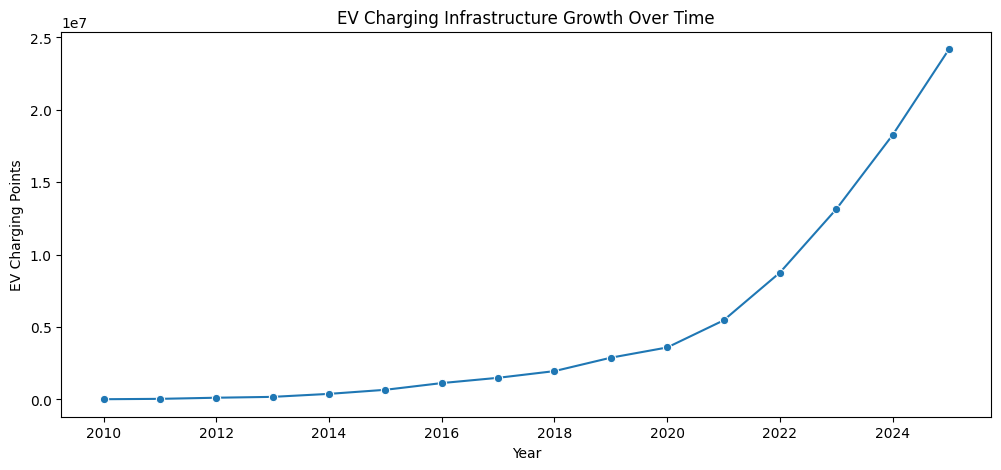

In [39]:
#Analyze EV charging infrastructure growth.	
charging = df[
    (df['parameter'] == 'EV charging points') &
    (df['category'] == 'Historical')
]

yearly_charging = charging.groupby('year')['value'].sum()

plt.figure(figsize=(12,5))
sns.lineplot(x=yearly_charging.index, y=yearly_charging.values, marker='o')

plt.title('EV Charging Infrastructure Growth Over Time')
plt.xlabel('Year')
plt.ylabel('EV Charging Points')
plt.show()

In [40]:
#Calculate charging points per 1,000 EVs.
charging = df[df['parameter'] == 'EV charging points']
stock = df[(df['parameter'] == 'EV stock') & (df['powertrain'] == 'EV')]

merged = pd.merge(charging, stock, on=['region_country', 'year', 'category'], suffixes=('_charging', '_stock'))

merged['Charging per 1000 EVs'] = (merged['value_charging'] / merged['value_stock']) * 1000

merged[['region_country', 'year', 'Charging per 1000 EVs']]

,region_country,year,Charging per 1000 EVs
0,Chile,2011,166.666667
1,Norway,2011,4.615385
2,Norway,2011,18000.000000
3,Portugal,2011,6.593407
4,Canada,2012,333.333333
...,...,...,...
5753,Middle East and Caspian,2025,0.192771
5754,Middle East and Caspian,2025,3.809524
5755,Middle East and Caspian,2025,0.040000
5756,Middle East and Caspian,2025,57.142857


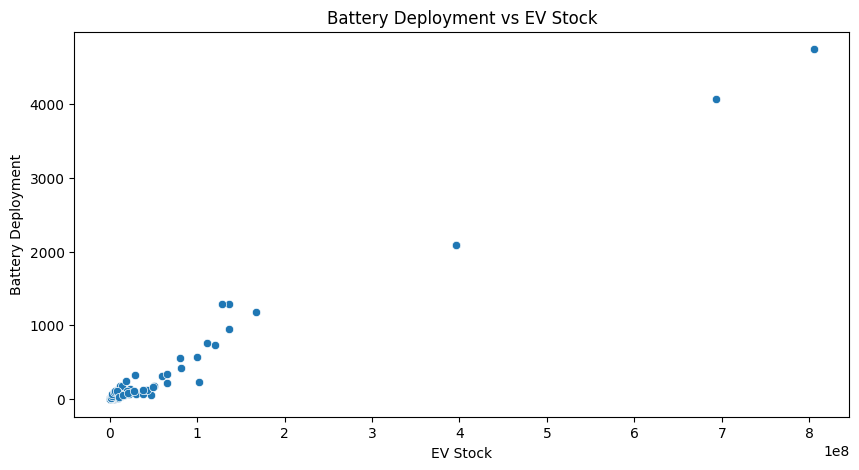

In [41]:
#Compare battery deployment with EV stock.


battery = df[df['parameter'] == 'Battery deployment']

stock = df[
    (df['parameter'] == 'EV stock') &
    (df['powertrain'] == 'EV')
]

battery = battery.groupby(['region_country', 'year', 'category'])['value'].sum().reset_index()

stock = stock.groupby(['region_country', 'year', 'category'])['value'].sum().reset_index()

merged = pd.merge(battery, stock, on=['region_country', 'year', 'category'], suffixes=('_battery', '_stock'))

plt.figure(figsize=(10,5))
sns.scatterplot(x=merged['value_stock'], y=merged['value_battery'])

plt.title('Battery Deployment vs EV Stock')
plt.xlabel('EV Stock')
plt.ylabel('Battery Deployment')
plt.show()

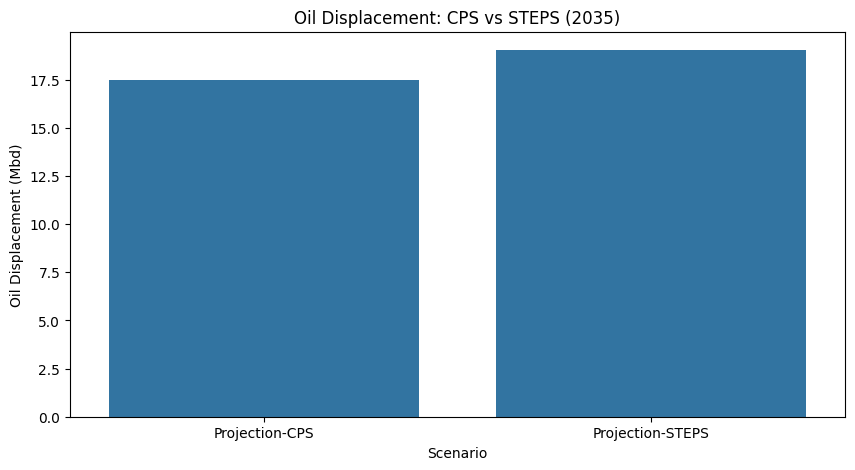

In [42]:
# Compare oil displacement between CPS and STEPS

oil = df[
    (df['parameter'] == 'Oil displacement, Mbd') &
    (df['category'].isin(['Projection-CPS', 'Projection-STEPS']))
]

yearly_oil = oil.groupby('category')['value'].sum()

plt.figure(figsize=(10,5))
sns.barplot(x=yearly_oil.index, y=yearly_oil.values)

plt.title('Oil Displacement: CPS vs STEPS (2035)')
plt.xlabel('Scenario')
plt.ylabel('Oil Displacement (Mbd)')
plt.show()

Correlation: 0.3002240365326407


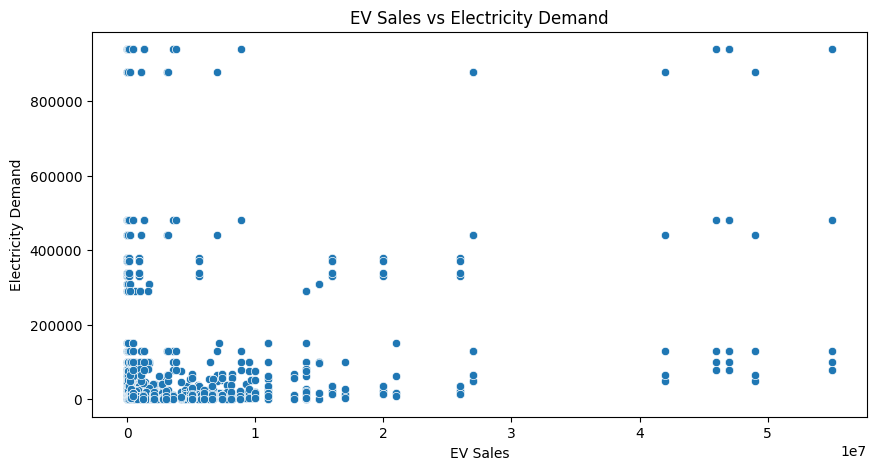

In [43]:
#Find the relationship between EV sales and electricity demand.
# EV Sales vs Electricity Demand

sales = df[df['parameter'] == 'EV sales']
electricity = df[df['parameter'] == 'Electricity demand']

merged = pd.merge(
    sales,
    electricity,
    on=['region_country', 'year', 'category'],
    suffixes=('_sales', '_electricity')
)

correlation = merged['value_sales'].corr(merged['value_electricity'])

print("Correlation:", correlation)

plt.figure(figsize=(10,5))
sns.scatterplot(x=merged['value_sales'], y=merged['value_electricity'])

plt.title('EV Sales vs Electricity Demand')
plt.xlabel('EV Sales')
plt.ylabel('Electricity Demand')
plt.show()

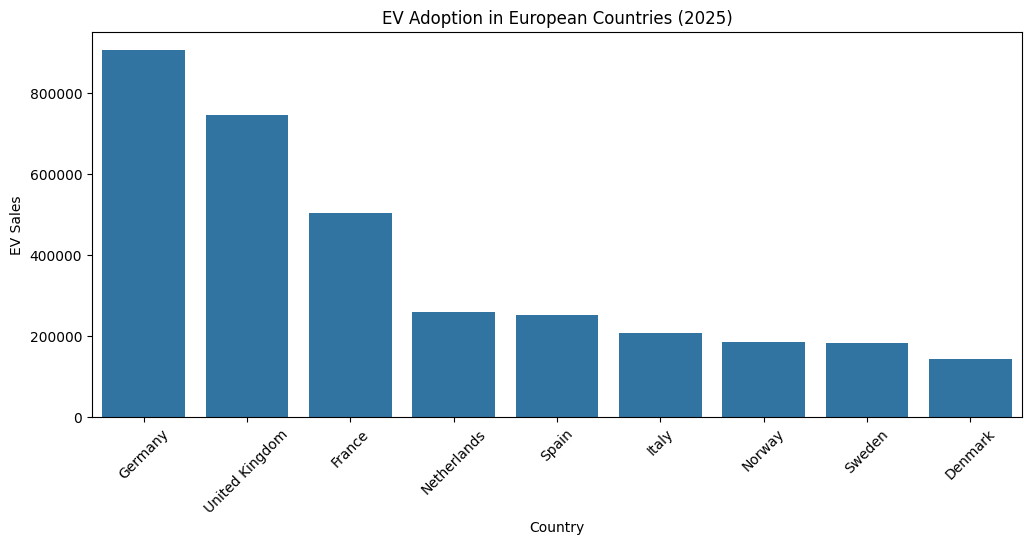

In [44]:
#	Analyze EV adoption in European countries.	
europe = df[
    (df['parameter'] == 'EV sales') &
    (df['category'] == 'Historical') &
    (df['year'] == 2025) &
    (df['powertrain'] == 'EV') &
    (df['region_country'].isin(['Norway', 'Germany', 'France', 'United Kingdom', 'Netherlands', 'Sweden', 'Denmark', 'Italy', 'Spain']))
]

europe_sales = europe.groupby('region_country')['value'].sum().sort_values(ascending=False)

plt.figure(figsize=(12,5))
sns.barplot(x=europe_sales.index, y=europe_sales.values)

plt.title('EV Adoption in European Countries (2025)')
plt.xlabel('Country')
plt.ylabel('EV Sales')
plt.xticks(rotation=45)
plt.show()


In [45]:
#Predict EV sales using year and country.
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
sales = df[
    (df['parameter'] == 'EV sales') &
    (df['category'] == 'Historical') &
    (df['powertrain'] == 'EV')
].dropna(subset=['region_country', 'year', 'value'])

X = sales[['region_country', 'year']]
y = sales['value']

preprocessor = ColumnTransformer([
    ('country', OneHotEncoder(handle_unknown='ignore'), ['region_country'])
], remainder='passthrough')

model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

train = sales[sales['year'] <= 2022]
test = sales[sales['year'] > 2022]

X_train = train[['region_country', 'year']]
y_train = train['value']

X_test = test[['region_country', 'year']]
y_test = test['value']

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 580818.9564360386
MSE: 3156324377050.3477
R2 Score: 0.16415327033918958


In [46]:
#Predict EV stock for a country.
from sklearn.ensemble import RandomForestRegressor

stock = df[(df['parameter'] == 'EV stock') & (df['category'] == 'Historical') & (df['powertrain'] == 'EV')]

X = pd.get_dummies(stock[['region_country', 'year']])
y = stock['value']

model = RandomForestRegressor(random_state=42)
model.fit(X, y)

model.predict(X)

array([9.93641962e+03, 2.26439596e+04, 4.46350290e+04, ...,
       2.34314396e+07, 2.75022717e+07, 3.18969909e+07])

In [47]:
#Classify countries into High and Low EV adoption.
from sklearn.linear_model import LogisticRegression

data = df[(df['parameter'] == 'EV sales') & (df['category'] == 'Historical') & (df['powertrain'] == 'EV') & (df['year'] == 2025)]

country = data.groupby('region_country')['value'].sum().reset_index()
country['Adoption'] = (country['value'] >= country['value'].median()).astype(int)

X = pd.get_dummies(country[['value']])
y = country['Adoption']

model = LogisticRegression()
model.fit(X, y)

country['Prediction'] = model.predict(X)
country['Result'] = country['Prediction'].map({1: 'High', 0: 'Low'})
print(country[['region_country', 'Result']])

        region_country Result
0   Advanced Economies   High
1               Africa   High
2         Asia Pacific   High
3            Australia   High
4              Austria   High
..                 ...    ...
65      United Kingdom   High
66             Uruguay    Low
67          Uzbekistan    Low
68            Viet Nam   High
69               World   High

[70 rows x 2 columns]


In [48]:
#Identify important factors affecting EV sales.
from sklearn.ensemble import RandomForestRegressor

data = df[(df['parameter'] == 'EV sales') & (df['category'] == 'Historical')]

features = data.pivot_table(index=['region_country', 'year'], columns='parameter', values='value', aggfunc='sum').reset_index()

X = pd.get_dummies(features.drop(columns=['EV sales']))
y = features['EV sales']

model = RandomForestRegressor(random_state=42)
model.fit(X, y)

importance = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)

print(importance)

year                                 4.600108e-01
region_country_World                 2.367318e-01
region_country_Asia Pacific          1.502778e-01
region_country_China                 1.324932e-01
region_country_Advanced Economies    1.073608e-02
                                         ...     
region_country_Jordan                1.940345e-09
region_country_Bulgaria              1.584238e-09
region_country_Cambodia              1.580250e-09
region_country_Seychelles            1.458427e-09
region_country_Lithuania             1.074306e-09
Length: 72, dtype: float64
